# 01 · LSTM com OHLCV: prever o preço ou o retorno?

Mesma rede, mesmos dados (OHLCV diário), duas formas de alvo:
- **preco**: entrada OHLCV em nível, a rede prevê o fechamento de amanhã;
- **retorno**: entrada OHLCV em variação em relação a ontem, a rede prevê a variação de amanhã. O preço sai de hoje × exp(retorno).

Referência: **naive** (amanhã = hoje). Divisão cronológica 70% treino, 15% validação, 15% teste; 5 sementes.

In [1]:
import os, sys, glob
achados = glob.glob('../src/tcc/config.py') + glob.glob('/kaggle/input/**/src/tcc/config.py', recursive=True)
RAIZ = achados[0].rsplit('/src/', 1)[0]              # pasta do projeto (no PC ou no dataset do Kaggle)
sys.path.insert(0, os.path.join(RAIZ, 'src'))
import warnings; warnings.filterwarnings('ignore')
import json, shutil
import pandas as pd, matplotlib.pyplot as plt
from tcc import config, experimento

In [2]:
ALVOS  = ['preco', 'retorno']
INICIO = '2022-01-01'
FIM    = '2023-12-31'
MOEDAS = config.MOEDAS

SAIDA = config.PASTA_RESULTADOS / '01_alvo'
SAIDA.mkdir(parents=True, exist_ok=True)

## Faixa de preço do treino x teste
Com alvo = preço, a rede só aprende valores dentro da faixa vista no treino.

In [3]:
faixa = pd.DataFrame([experimento.faixa_do_treino(m, INICIO, FIM) for m in MOEDAS])
faixa.to_csv(SAIDA / 'faixa_precos.csv', index=False)
faixa.round(2)

,moeda,treino,teste,min_treino,max_treino,teste_fora_da_faixa_%
0,BTC,2022-01-02 a 2023-05-26,2023-09-13 a 2023-12-31,15787.28,47465.73,0.0
1,ETH,2022-01-02 a 2023-05-26,2023-09-13 a 2023-12-31,993.64,3829.56,0.0
2,SOL,2022-01-02 a 2023-05-26,2023-09-13 a 2023-12-31,9.65,176.38,0.0
3,BNB,2022-01-02 a 2023-05-26,2023-09-13 a 2023-12-31,197.04,531.40,0.0
4,DOGE,2022-01-02 a 2023-05-26,2023-09-13 a 2023-12-31,0.05,0.19,0.0


## Treino e teste

In [4]:
prev = pd.concat([experimento.rodar(m, a, INICIO, FIM) for m in MOEDAS for a in ALVOS], ignore_index=True)
prev.to_csv(SAIDA / 'previsoes.csv', index=False)
resumo = experimento.resumir(prev)
resumo.round(4).to_csv(SAIDA / 'resumo.csv', index=False)
resumo.round(3)

,moeda,alvo,MAPE_%,desvio_sementes,MAPE_naive_%,RMSE,acerto_direcao_%,DM_vs_naive,p_vs_naive,dias_teste
0,BTC,preco,1.857,0.093,1.449,943.750,49.091,3.392,0.001,110
1,BTC,retorno,1.459,0.008,1.449,777.180,50.909,0.411,0.682,110
2,ETH,preco,1.976,0.064,1.650,53.323,45.455,2.830,0.006,110
3,ETH,retorno,1.699,0.009,1.650,49.236,43.636,1.847,0.067,110
4,SOL,preco,5.338,0.433,4.015,4.605,49.091,3.053,0.003,110
5,SOL,retorno,4.046,0.025,4.015,3.416,49.091,0.174,0.862,110
6,BNB,preco,1.971,0.131,1.533,8.561,57.273,2.456,0.016,110
7,BNB,retorno,1.612,0.011,1.533,6.503,40.909,2.579,0.011,110
8,DOGE,preco,2.442,0.029,2.135,0.003,52.727,1.587,0.115,110
9,DOGE,retorno,2.165,0.014,2.135,0.002,42.727,0.745,0.458,110


In [5]:
tabela = resumo.pivot(index='moeda', columns='alvo', values='MAPE_%').loc[MOEDAS]
tabela.insert(0, 'naive', resumo.groupby('moeda')['MAPE_naive_%'].first())
tabela.loc['média'] = tabela.mean()
tabela.round(2)

alvo,naive,preco,retorno
moeda,,,
BTC,1.45,1.86,1.46
ETH,1.65,1.98,1.70
SOL,4.01,5.34,4.05
BNB,1.53,1.97,1.61
DOGE,2.14,2.44,2.16
média,2.16,2.72,2.20


## Previsões no teste

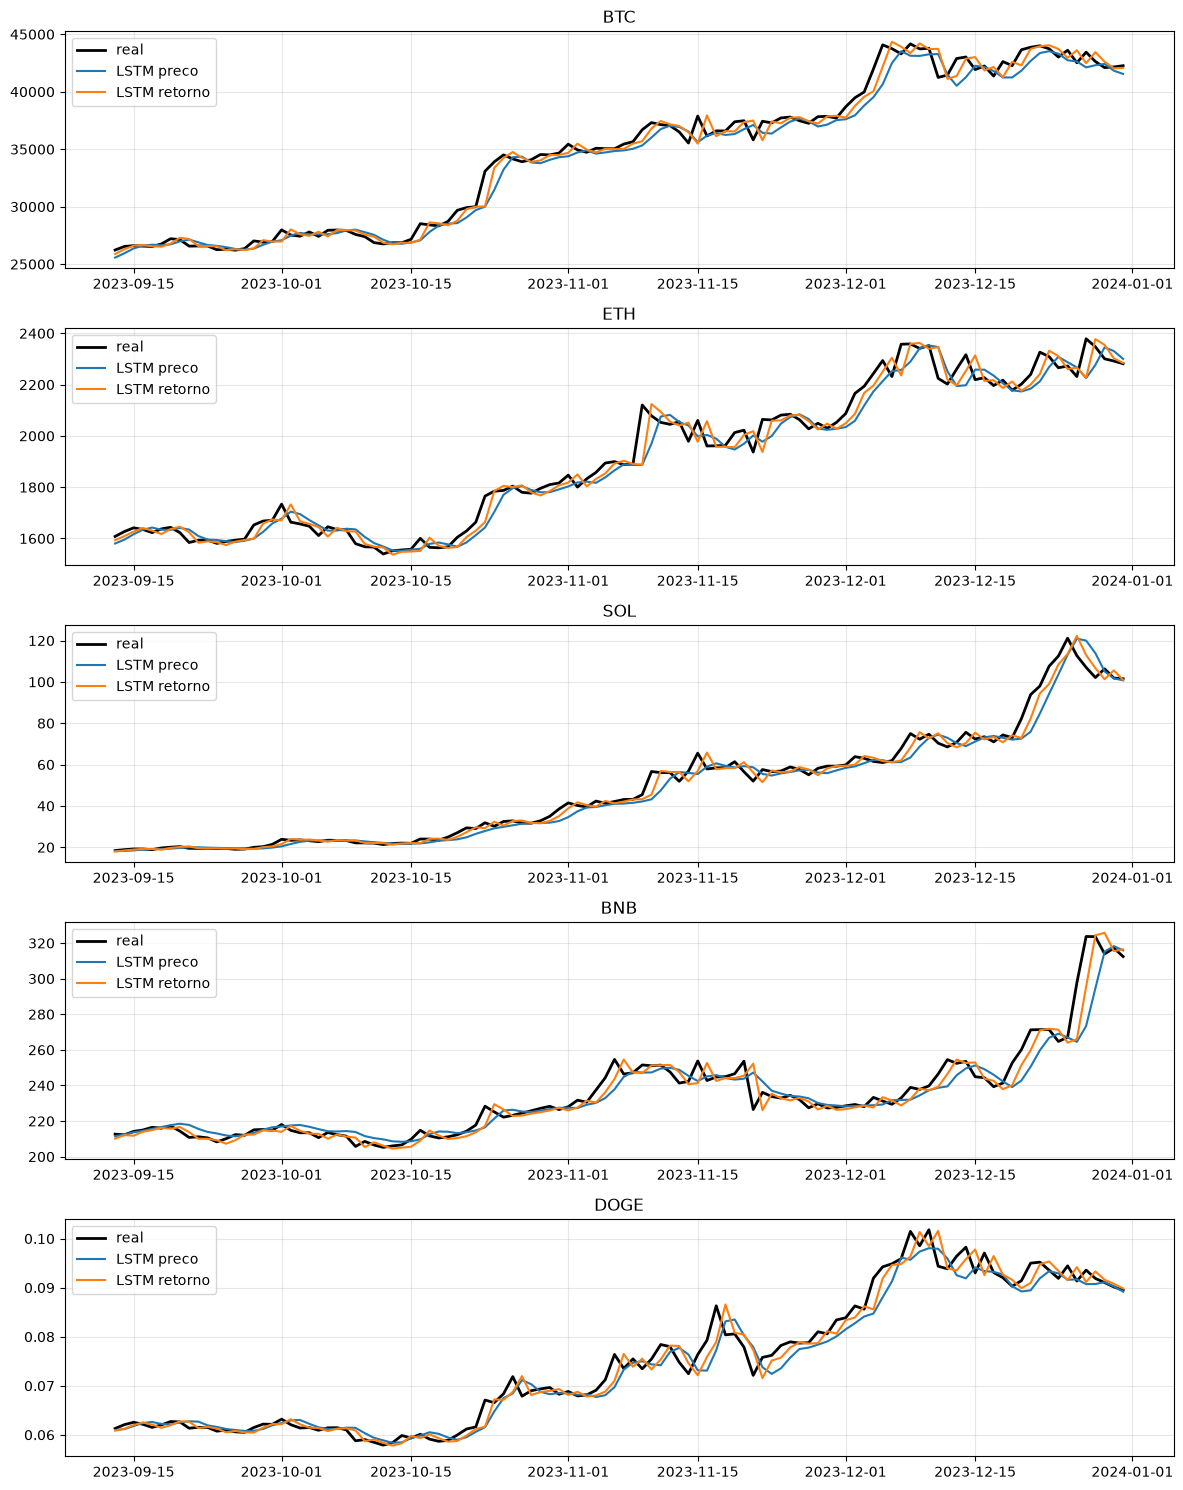

In [6]:
fig, eixos = plt.subplots(len(MOEDAS), 1, figsize=(12, 3 * len(MOEDAS)))
for ax, moeda in zip(eixos, MOEDAS):
    g = prev[prev.moeda == moeda].groupby(['alvo', 'data'])[['real', 'previsto']].mean()
    real = g.loc[ALVOS[0], 'real']
    ax.plot(real.index, real, 'k', lw=2, label='real')
    for alvo in ALVOS:
        ax.plot(g.loc[alvo].index, g.loc[alvo, 'previsto'], label=f'LSTM {alvo}')
    ax.set_title(moeda); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(SAIDA / 'previsoes.png', dpi=130); plt.show()

In [7]:
(SAIDA / 'config.json').write_text(json.dumps({'inicio': INICIO, 'fim': FIM, 'alvos': ALVOS, 'moedas': MOEDAS,
    'sementes': config.SEMENTES, 'hp': config.HP_LSTM, 'frac_validacao': config.FRAC_VALIDACAO,
    'frac_teste': config.FRAC_TESTE}, indent=2))
print('Pronto:', shutil.make_archive(str(SAIDA), 'zip', SAIDA))

Pronto: /mnt/attach/project-files/tcc-sentimento-cripto/results/01_alvo.zip
